# Restaurant Dataset - Business Analysis

Level 2 - Task 1 & 2

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("../Cleaned_Dataset.csv")

df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


### Part A - Table Booking Analysis

In [3]:
df["Has Table booking"].value_counts()

Has Table booking
No     8393
Yes    1158
Name: count, dtype: int64

In [4]:
df["Has Table booking"].value_counts()

Has Table booking
No     8393
Yes    1158
Name: count, dtype: int64

In [5]:
booking_percent = (
    df["Has Table booking"]
    .value_counts(normalize=True)
    * 100
)

booking_percent.round(2)

Has Table booking
No     87.88
Yes    12.12
Name: proportion, dtype: float64

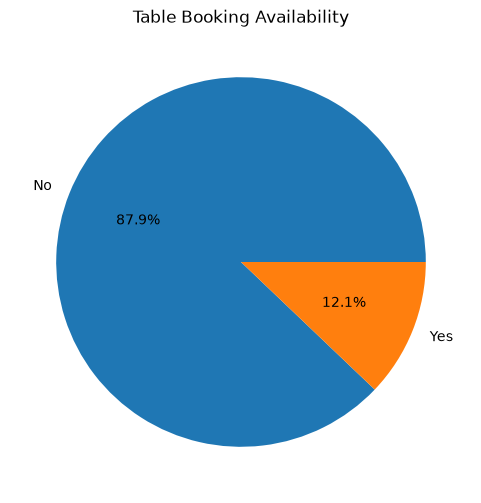

In [6]:
plt.figure(figsize=(6,6))

booking_percent.plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.ylabel("")
plt.title("Table Booking Availability")

plt.show()

In [7]:
df.groupby("Has Table booking")["Aggregate rating"].mean()

Has Table booking
No     2.559359
Yes    3.441969
Name: Aggregate rating, dtype: float64

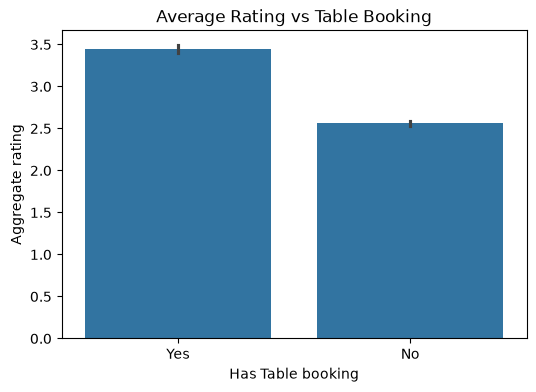

In [8]:
plt.figure(figsize=(6,4))

sns.barplot(
    data=df,
    x="Has Table booking",
    y="Aggregate rating"
)

plt.title("Average Rating vs Table Booking")

plt.show()

### Part B - Online Delivery Analysis

In [9]:
df["Has Online delivery"].value_counts()

Has Online delivery
No     7100
Yes    2451
Name: count, dtype: int64

In [10]:
delivery_percent = (
    df["Has Online delivery"]
    .value_counts(normalize=True)
    * 100
)

delivery_percent.round(2)

Has Online delivery
No     74.34
Yes    25.66
Name: proportion, dtype: float64

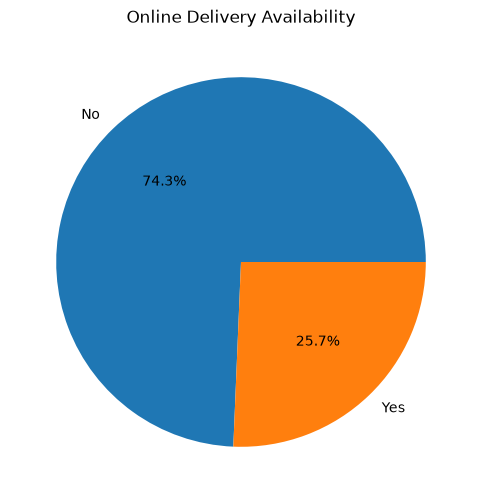

In [11]:
plt.figure(figsize=(6,6))

delivery_percent.plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.ylabel("")
plt.title("Online Delivery Availability")

plt.show()

In [12]:
df.groupby("Has Online delivery")["Aggregate rating"].mean()

Has Online delivery
No     2.465296
Yes    3.248837
Name: Aggregate rating, dtype: float64

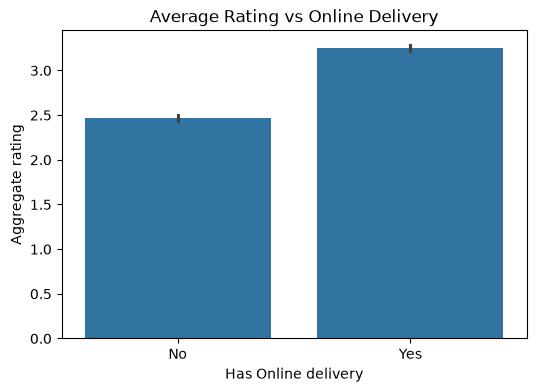

In [13]:
plt.figure(figsize=(6,4))

sns.barplot(
    data=df,
    x="Has Online delivery",
    y="Aggregate rating"
)

plt.title("Average Rating vs Online Delivery")

plt.show()

### Part C : Price Range Analysis

In [14]:
price_counts = df["Price range"].value_counts().sort_index()

price_counts

Price range
1    4444
2    3113
3    1408
4     586
Name: count, dtype: int64

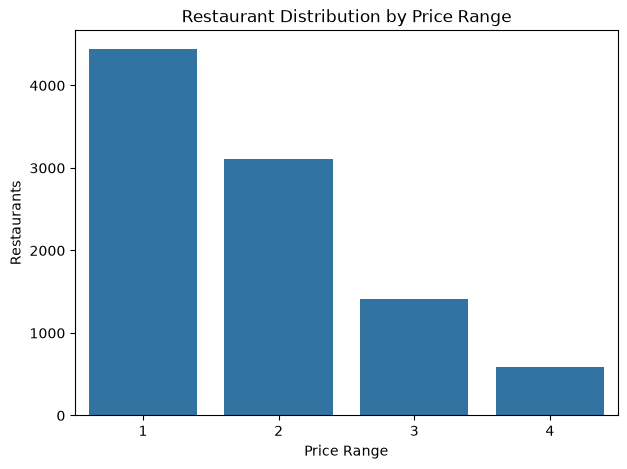

In [15]:
plt.figure(figsize=(7,5))

sns.barplot(
    x=price_counts.index,
    y=price_counts.values
)

plt.title("Restaurant Distribution by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Restaurants")

plt.show()

In [16]:
price_rating = (
    df.groupby("Price range")["Aggregate rating"]
    .mean()
)

price_rating

Price range
1    1.999887
2    2.941054
3    3.683381
4    3.817918
Name: Aggregate rating, dtype: float64

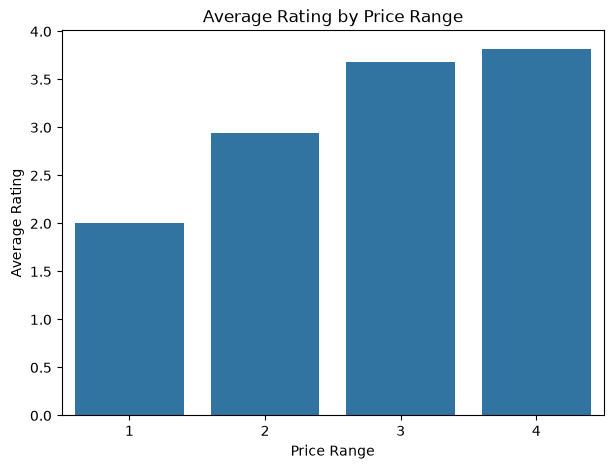

In [17]:
plt.figure(figsize=(7,5))

sns.barplot(
    x=price_rating.index,
    y=price_rating.values
)

plt.title("Average Rating by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Average Rating")

plt.show()

In [18]:
pd.crosstab(
    df["Price range"],
    df["Has Online delivery"]
)

Has Online delivery,No,Yes
Price range,,
1,3743,701
2,1827,1286
3,997,411
4,533,53


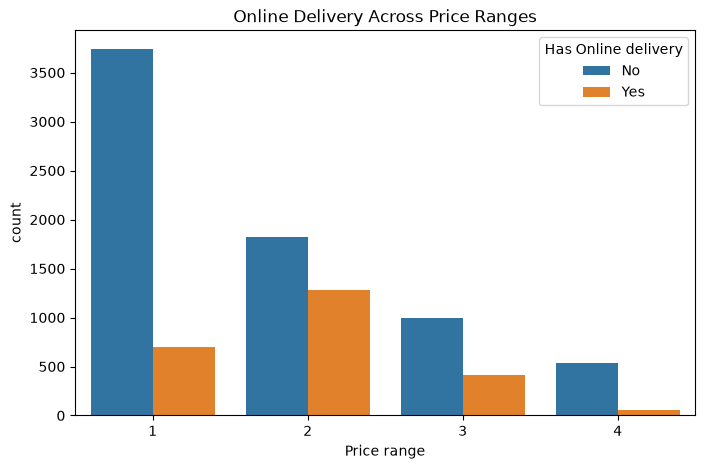

In [19]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Price range",
    hue="Has Online delivery"
)

plt.title("Online Delivery Across Price Ranges")

plt.show()

In [20]:
highest = price_rating.idxmax()
rating = price_rating.max()

print(f"Highest Rated Price Range: {highest}")
print(f"Average Rating: {rating:.2f}")

Highest Rated Price Range: 4
Average Rating: 3.82


In [21]:
color_rating = (
    df.groupby("Rating color")["Aggregate rating"]
    .mean()
    .sort_values(ascending=False)
)

color_rating

Rating color
Dark Green    4.659801
Green         4.168119
Yellow        3.683429
Orange        3.051619
Red           2.297849
White         0.000000
Name: Aggregate rating, dtype: float64

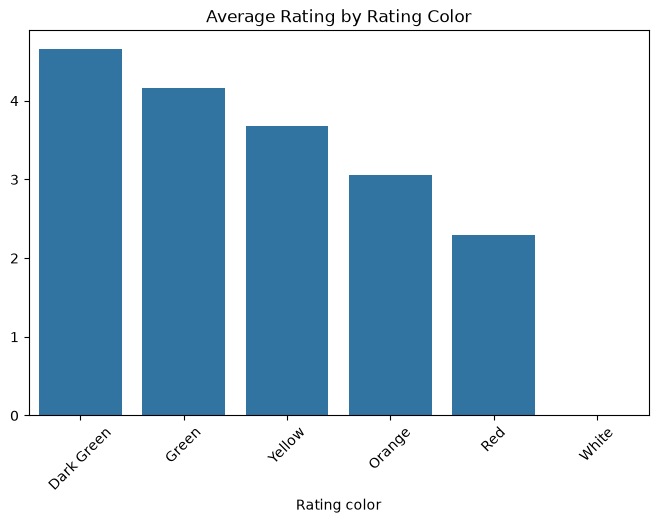

In [22]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=color_rating.index,
    y=color_rating.values
)

plt.title("Average Rating by Rating Color")
plt.xticks(rotation=45)

plt.show()

### Business Insights

- Most restaurants do not provide table booking.
- Online delivery is available for only a subset of restaurants.
- Restaurants offering table booking generally receive higher average ratings.
- Online delivery is more common in specific price ranges.
- The highest-rated restaurants belong to Price Range __.
- Rating Color Dark Green corresponds to the highest average rating.## Business Insights